# 04 · Exploratory Data Analysis

**Input:** the clean layer (notebook 02) and the signal tables (notebook 03) in `data/warehouse/volvo.duckdb`.

**Questions**
1. How do summer and winter trips differ?
2. How much energy does cabin heating take, and what drives it?
3. What drives energy consumption per 100 km?
4. How does voltage sag (and apparent pack resistance) depend on temperature?
5. Which variables move together?

**Ground rules:** there are only 32 summer and 38 winter trips, so results are reported with medians, spread and
rank-based tests (Mann-Whitney U, Spearman), never a single average. Summer and winter trips also differ in route and
speed, so every season effect is checked against those confounders before it is interpreted.

In [1]:
from pathlib import Path
import textwrap

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = ROOT / "data" / "warehouse" / "volvo.duckdb"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
SEASON_COLORS = {"summer": "#e6550d", "winter": "#3182bd"}

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
con = duckdb.connect(str(DB_PATH), read_only=True)

## 0 · One table per trip

In [2]:
trip = con.sql("""
    WITH drive AS (
        SELECT c.trip_id,
               avg(c.speed_kmh)              AS mean_driving_speed_kmh,
               avg(abs(c.accel_long_ms2))    AS mean_abs_accel_ms2,
               avg(c.ambient_temp_c)         AS ambient_mean_c,
               avg(c.heating_power_can_kw)   AS heating_mean_kw,
               avg(c.aircon_power_kw)        AS aircon_mean_kw,
               max(c.elevation_m) - min(c.elevation_m) AS elevation_range_m
        FROM clean.trip_signals c JOIN signal.samples s USING (trip_id, row_idx)
        WHERE s.phase = 'driving'
        GROUP BY 1),
    stops AS (
        SELECT trip_id, count(*) FILTER (WHERE phase = 'stopped') AS stops,
               coalesce(sum(duration_s) FILTER (WHERE phase = 'stopped'), 0) / sum(duration_s) AS stopped_share
        FROM signal.segments GROUP BY 1),
    sag AS (
        SELECT trip_id, count(*) AS sag_events, median(apparent_resistance_mohm) AS resistance_median_mohm
        FROM signal.sag_events GROUP BY 1)
    SELECT t.trip_id, t.season, t.route, t.weather, t.target_cabin_temp_c,
           e.distance_km_integrated AS distance_km, e.driving_h, e.energy_out_kwh, e.energy_regen_kwh,
           e.energy_net_drive_kwh, e.heating_kwh, e.aircon_kwh, e.consumption_kwh_per_100km,
           e.regen_share_pct, e.heating_share_pct, e.energy_charged_kwh,
           r.batt_temp_start_c, r.rise_c AS batt_temp_rise_c, r.rise_rate_c_per_h AS batt_temp_rise_rate_c_per_h,
           d.* EXCLUDE (trip_id), st.stops, st.stopped_share, coalesce(sg.sag_events, 0) AS sag_events, sg.resistance_median_mohm
    FROM clean.trips t
    JOIN signal.trip_energy e USING (trip_id)
    JOIN signal.temp_rise r USING (trip_id)
    JOIN drive d USING (trip_id)
    JOIN stops st USING (trip_id)
    LEFT JOIN sag sg USING (trip_id)
    ORDER BY t.trip_id
""").df()
trip["sag_events_per_10km"] = 10 * trip.sag_events / trip.distance_km
trip["traction_kwh_per_100km"] = 100 * (trip.energy_net_drive_kwh - trip.heating_kwh - trip.aircon_kwh) / trip.distance_km
trip["heating_kwh_per_100km"] = 100 * trip.heating_kwh / trip.distance_km
assert trip.trip_id.is_unique and len(trip) == 70
print(trip.shape)
trip.head(3)

(70, 32)


,trip_id,season,route,weather,target_cabin_temp_c,distance_km,driving_h,energy_out_kwh,energy_regen_kwh,energy_net_drive_kwh,heating_kwh,aircon_kwh,consumption_kwh_per_100km,regen_share_pct,heating_share_pct,energy_charged_kwh,batt_temp_start_c,batt_temp_rise_c,batt_temp_rise_rate_c_per_h,mean_driving_speed_kmh,mean_abs_accel_ms2,ambient_mean_c,heating_mean_kw,aircon_mean_kw,elevation_range_m,stops,stopped_share,sag_events,resistance_median_mohm,sag_events_per_10km,traction_kwh_per_100km,heating_kwh_per_100km
0,TripA01,summer,Munich East,sunny,23.0,7.427969,0.245139,1.672606,0.383412,1.289195,0.000011,0.451362,17.355948,22.923010,0.000664,0.0,21.0,1.0,4.079320,30.295794,0.565514,30.697430,0.000046,1.598147,16.0,8,0.125372,0,NaN,0.000000,11.279284,0.000150
1,TripA02,summer,Munich East,sunny,23.0,23.514387,0.392500,4.585287,1.650492,2.934796,0.000035,0.179197,12.480851,35.995382,0.000757,0.0,23.0,3.0,7.643312,59.909267,0.574745,31.127573,0.000089,0.456553,43.0,0,0.000000,7,87.271196,2.976901,11.718629,0.000148
2,TripA03,summer,Munich East,sunny,27.0,12.820846,0.178556,2.409294,0.454845,1.954449,0.047649,0.078418,15.244306,18.878766,1.977712,0.0,24.0,2.0,11.200996,71.800520,0.462004,23.359443,1.423376,0.402225,13.0,4,0.041455,2,77.866025,1.559959,14.261007,0.371652


## 1 · Summer vs winter

Medians with interquartile range, and a two-sided Mann-Whitney U test per variable.

In [3]:
COMPARE = {
    "ambient_mean_c": "ambient temperature (°C)",
    "batt_temp_start_c": "battery temperature at start (°C)",
    "distance_km": "distance (km)",
    "mean_driving_speed_kmh": "mean driving speed (km/h)",
    "stopped_share": "share of time stopped",
    "consumption_kwh_per_100km": "consumption (kWh/100 km)",
    "heating_kwh_per_100km": "heating (kWh/100 km)",
    "traction_kwh_per_100km": "consumption without heating and A/C (kWh/100 km)",
    "regen_share_pct": "energy recovered by regeneration (%)",
    "batt_temp_rise_c": "battery temperature rise (°C)",
    "resistance_median_mohm": "apparent pack resistance (mΩ)",
    "sag_events_per_10km": "voltage-sag events per 10 km",
}


def iqr_text(x):
    return f"{x.median():.1f} [{x.quantile(.25):.1f}–{x.quantile(.75):.1f}]"


rows = []
for col, label in COMPARE.items():
    a = trip.loc[trip.season == "summer", col].dropna()
    b = trip.loc[trip.season == "winter", col].dropna()
    p = stats.mannwhitneyu(a, b, alternative="two-sided").pvalue
    rows.append({"variable": label, "summer median [IQR]": iqr_text(a), "winter median [IQR]": iqr_text(b),
                 "winter / summer": round(b.median() / a.median(), 2) if abs(a.median()) >= 0.1 else np.nan,
                 "p (Mann-Whitney)": f"{p:.1g}", "n summer/winter": f"{len(a)}/{len(b)}"})
season_table = pd.DataFrame(rows)
season_table.to_csv(REPORTS / "04_season_comparison.csv", index=False)
season_table

,variable,summer median [IQR],winter median [IQR],winter / summer,p (Mann-Whitney),n summer/winter
0,ambient temperature (°C),22.3 [18.6–25.2],5.1 [3.4–6.5],0.23,8e-13,32/38
1,battery temperature at start (°C),20.5 [18.8–23.2],9.0 [5.2–11.0],0.44,1e-11,32/38
2,distance (km),16.1 [11.6–19.4],16.7 [14.8–19.2],1.04,0.2,32/38
3,mean driving speed (km/h),46.6 [34.0–61.7],54.1 [48.0–64.5],1.16,0.06,32/38
4,share of time stopped,0.1 [0.1–0.1],0.1 [0.1–0.2],NaN,0.03,32/38
5,consumption (kWh/100 km),13.3 [12.2–15.1],19.1 [17.4–20.9],1.43,5e-11,32/38
6,heating (kWh/100 km),0.0 [0.0–0.6],3.8 [2.8–4.7],NaN,6e-12,32/38
7,consumption without heating and A/C (kWh/100 km),12.1 [10.8–13.2],15.1 [14.5–15.9],1.25,7e-07,32/38
8,energy recovered by regeneration (%),23.1 [17.7–30.5],11.6 [9.0–14.5],0.50,2e-07,32/38
9,battery temperature rise (°C),1.0 [1.0–2.0],3.0 [2.0–4.0],3.00,1e-05,32/38


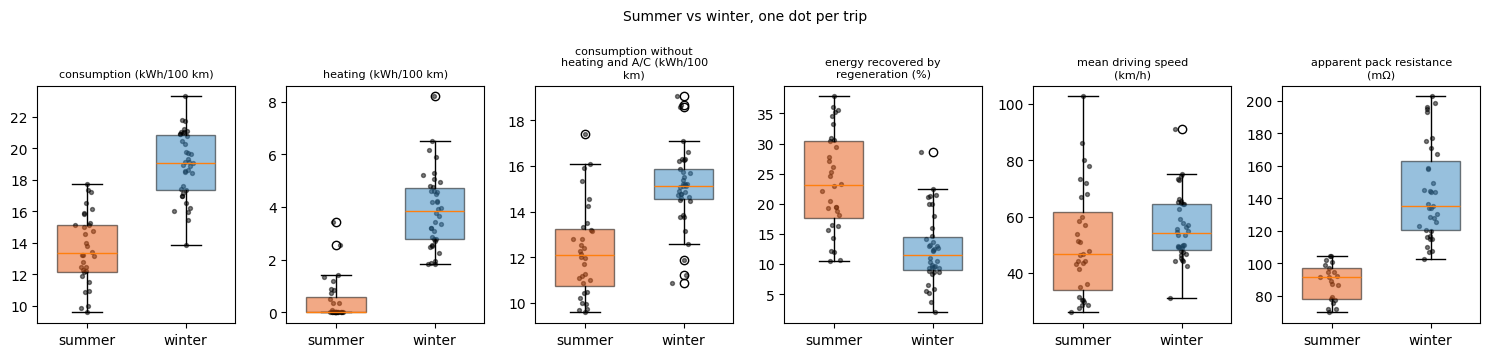

In [4]:
show = ["consumption_kwh_per_100km", "heating_kwh_per_100km", "traction_kwh_per_100km", "regen_share_pct",
        "mean_driving_speed_kmh", "resistance_median_mohm"]
fig, axes = plt.subplots(1, len(show), figsize=(15, 3.6))
for ax, col in zip(axes, show):
    data = [trip.loc[trip.season == s, col].dropna() for s in SEASON_COLORS]
    bp = ax.boxplot(data, tick_labels=list(SEASON_COLORS), patch_artist=True, widths=0.6)
    for patch, c in zip(bp["boxes"], SEASON_COLORS.values()):
        patch.set_facecolor(c)
        patch.set_alpha(0.5)
    for i, d in enumerate(data, start=1):
        ax.scatter(np.random.default_rng(0).normal(i, 0.05, len(d)), d, s=8, color="k", alpha=0.5)
    ax.set_title("\n".join(textwrap.wrap(COMPARE[col], 24)), fontsize=8)
fig.suptitle("Summer vs winter, one dot per trip", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES / "04_summer_vs_winter.png", dpi=150)
plt.show()

**Confounder check:** the seasons were driven on different routes (summer mostly Munich East, winter mostly
Munich North, the test route and highway). Do the seasons differ in *how* the car was driven?

In [5]:
print(pd.crosstab(trip.route, trip.season).to_string())
print()
for col in ["mean_driving_speed_kmh", "mean_abs_accel_ms2", "stopped_share", "elevation_range_m"]:
    a, b = (trip.loc[trip.season == s, col] for s in ("summer", "winter"))
    print(f"{col:24s} summer {a.median():6.2f} | winter {b.median():6.2f} | p = {stats.mannwhitneyu(a, b).pvalue:.2g}")

season                        summer  winter
route                                       
FTMRoute                           0       7
FTMRoute (2x)                      0       1
FTMRoute reverse                   0       1
Highway                            0       3
Munich East                       30       1
Munich North                       2      19
Munich North + Fast Charging       0       1
Munich Northeast                   0       2
Munich South                       0       3

mean_driving_speed_kmh   summer  46.58 | winter  54.13 | p = 0.062
mean_abs_accel_ms2       summer   0.49 | winter   0.46 | p = 0.28
stopped_share            summer   0.09 | winter   0.12 | p = 0.034
elevation_range_m        summer  30.00 | winter  31.25 | p = 0.85


## 2 · Heating load

In [6]:
winter = trip[trip.season == "winter"]
rho, p = stats.spearmanr(winter.ambient_mean_c, winter.heating_mean_kw)
print(f"winter trips: heating power vs ambient temperature, Spearman rho = {rho:.2f} (p = {p:.2g})")
rho2, p2 = stats.spearmanr(trip.ambient_mean_c, trip.heating_share_pct)
print(f"all trips: heating share of battery energy vs ambient temperature, rho = {rho2:.2f} (p = {p2:.2g})")
print(f"heating share of battery energy, winter median {winter.heating_share_pct.median():.1f} %, "
      f"max {winter.heating_share_pct.max():.1f} % ({winter.trip_id[winter.heating_share_pct.idxmax()]})")

winter trips: heating power vs ambient temperature, Spearman rho = -0.39 (p = 0.015)
all trips: heating share of battery energy vs ambient temperature, rho = -0.77 (p = 4.1e-15)
heating share of battery energy, winter median 18.0 %, max 30.0 % (TripB02)


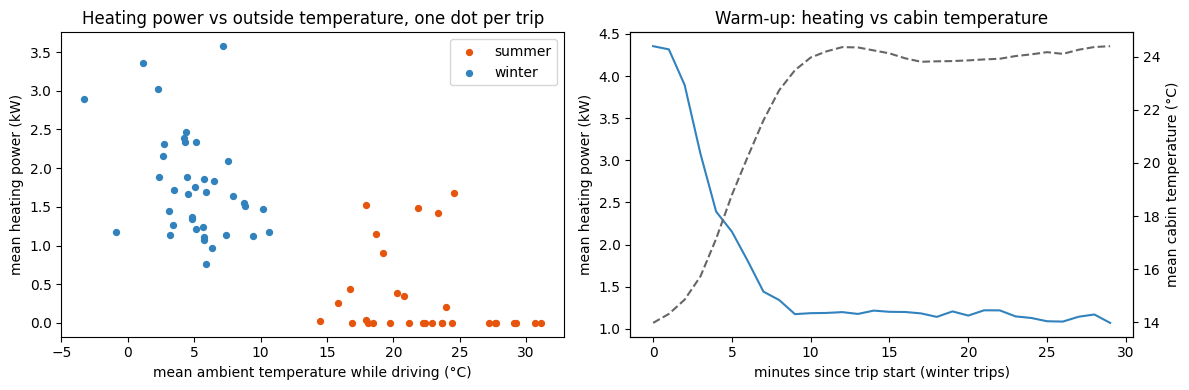

winter mean heating power: first 5 min 3.61 kW, minutes 15-29 1.16 kW


In [7]:
# heating power over the first 30 minutes of every winter trip: is there a warm-up peak?
prof = con.sql("""
    SELECT floor(c.time_s / 60) AS minute, avg(c.heating_power_can_kw) AS heating_kw,
           avg(c.cabin_temp_c) AS cabin_c, count(DISTINCT c.trip_id) AS trips
    FROM clean.trip_signals c WHERE c.series = 'B' AND c.time_s < 1800
    GROUP BY 1 ORDER BY 1
""").df()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for s, c in SEASON_COLORS.items():
    d = trip[trip.season == s]
    axes[0].scatter(d.ambient_mean_c, d.heating_mean_kw, s=18, color=c, label=s)
axes[0].set_xlabel("mean ambient temperature while driving (°C)")
axes[0].set_ylabel("mean heating power (kW)")
axes[0].set_title("Heating power vs outside temperature, one dot per trip")
axes[0].legend()
axes[1].plot(prof.minute, prof.heating_kw, color=SEASON_COLORS["winter"], label="heating power (kW)")
ax2 = axes[1].twinx()
ax2.plot(prof.minute, prof.cabin_c, color="0.4", ls="--", label="cabin temperature (°C)")
axes[1].set_xlabel("minutes since trip start (winter trips)")
axes[1].set_ylabel("mean heating power (kW)")
ax2.set_ylabel("mean cabin temperature (°C)")
axes[1].set_title("Warm-up: heating vs cabin temperature")
fig.tight_layout()
fig.savefig(FIGURES / "04_heating_load.png", dpi=150)
plt.show()
early, late = prof.loc[prof.minute < 5, "heating_kw"].mean(), prof.loc[prof.minute.between(15, 29), "heating_kw"].mean()
print(f"winter mean heating power: first 5 min {early:.2f} kW, minutes 15-29 {late:.2f} kW")

## 3 · What drives consumption?

In [8]:
drivers = ["ambient_mean_c", "mean_driving_speed_kmh", "mean_abs_accel_ms2", "stopped_share", "heating_mean_kw",
           "elevation_range_m", "distance_km"]
rows = []
for target in ["consumption_kwh_per_100km", "traction_kwh_per_100km"]:
    for d in drivers:
        rho, p = stats.spearmanr(trip[d], trip[target], nan_policy="omit")
        rows.append(dict(target=target, driver=d, spearman_rho=round(rho, 2), p=f"{p:.1g}"))
drivers_table = pd.DataFrame(rows).pivot(index="driver", columns="target", values="spearman_rho")
drivers_table.sort_values("consumption_kwh_per_100km", key=abs, ascending=False)

target,consumption_kwh_per_100km,traction_kwh_per_100km
driver,,
heating_mean_kw,0.80,0.57
ambient_mean_c,-0.73,-0.59
mean_driving_speed_kmh,0.36,0.55
stopped_share,0.21,0.17
elevation_range_m,-0.07,0.02
distance_km,-0.04,0.02
mean_abs_accel_ms2,-0.03,-0.12


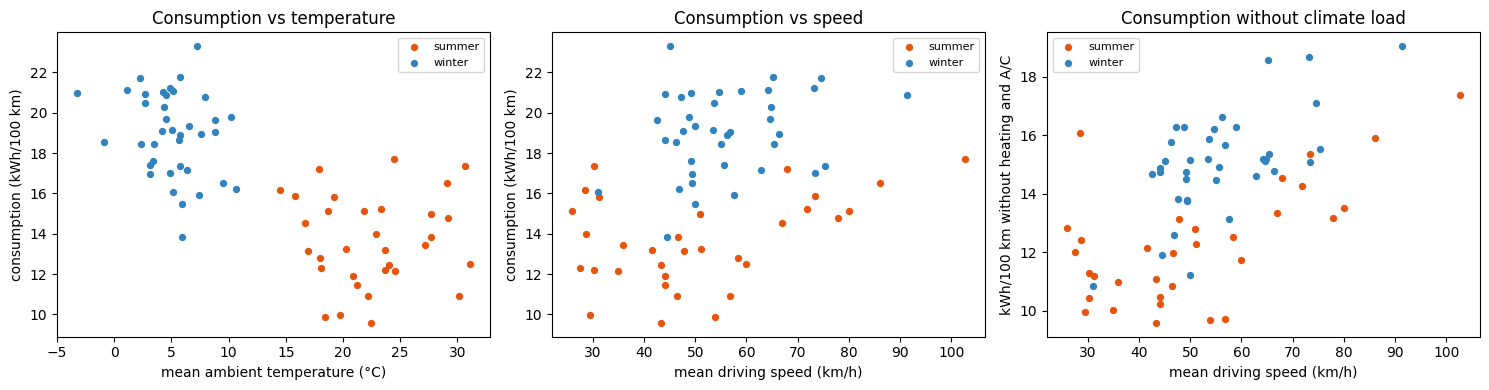

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for s, c in SEASON_COLORS.items():
    d = trip[trip.season == s]
    axes[0].scatter(d.ambient_mean_c, d.consumption_kwh_per_100km, s=18, color=c, label=s)
    axes[1].scatter(d.mean_driving_speed_kmh, d.consumption_kwh_per_100km, s=18, color=c, label=s)
    axes[2].scatter(d.mean_driving_speed_kmh, d.traction_kwh_per_100km, s=18, color=c, label=s)
axes[0].set(xlabel="mean ambient temperature (°C)", ylabel="consumption (kWh/100 km)", title="Consumption vs temperature")
axes[1].set(xlabel="mean driving speed (km/h)", ylabel="consumption (kWh/100 km)", title="Consumption vs speed")
axes[2].set(xlabel="mean driving speed (km/h)", ylabel="kWh/100 km without heating and A/C",
            title="Consumption without climate load")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "04_consumption_drivers.png", dpi=150)
plt.show()

In [10]:
# How much of the winter penalty is heating? Compare medians of total vs climate-free consumption.
med = trip.groupby("season")[["consumption_kwh_per_100km", "traction_kwh_per_100km", "heating_kwh_per_100km"]].median()
gap_total = med.loc["winter", "consumption_kwh_per_100km"] - med.loc["summer", "consumption_kwh_per_100km"]
gap_traction = med.loc["winter", "traction_kwh_per_100km"] - med.loc["summer", "traction_kwh_per_100km"]
print(med.round(1).to_string())
print(f"\nwinter penalty in median consumption: {gap_total:+.1f} kWh/100 km; "
      f"without heating and A/C: {gap_traction:+.1f} kWh/100 km")

        consumption_kwh_per_100km  traction_kwh_per_100km  heating_kwh_per_100km
season                                                                          
summer                       13.3                    12.1                    0.0
winter                       19.1                    15.1                    3.8

winter penalty in median consumption: +5.7 kWh/100 km; without heating and A/C: +3.1 kWh/100 km


### 3b · Why is winter consumption still higher once heating is removed?

Two explanations can be tested with this data: winter trips were driven a little faster, and a cold battery
might accept less energy back during braking.

In [11]:
# 1) control for speed: least squares, consumption without climate load ~ speed + winter
X = np.column_stack([np.ones(len(trip)), trip.mean_driving_speed_kmh, (trip.season == "winter").astype(float)])
coef = np.linalg.lstsq(X, trip.traction_kwh_per_100km, rcond=None)[0]
print(f"controlling for speed: +{coef[1]:.3f} kWh/100 km per km/h, winter effect {coef[2]:+.1f} kWh/100 km")

# 2) speed-matched trips only
matched = trip[trip.mean_driving_speed_kmh.between(45, 65)]
print("\ntrips with mean driving speed 45-65 km/h:")
print(matched.groupby("season").agg(trips=("trip_id", "size"), speed=("mean_driving_speed_kmh", "median"),
                                    without_climate=("traction_kwh_per_100km", "median"),
                                    regen_share=("regen_share_pct", "median")).round(1).to_string())

# 3) does a cold battery limit regeneration?
rho, p = stats.spearmanr(trip.batt_temp_start_c, trip.regen_share_pct)
print(f"\nregen share vs battery temperature at start: rho = {rho:.2f} (p = {p:.1g})")
regen_limit = con.sql("""
    SELECT floor(c.batt_temp_c / 5) * 5 AS batt_temp_band_c,
           quantile_cont(c.batt_current_a, 0.99) AS regen_current_p99_a, count(*) AS samples
    FROM clean.trip_signals c JOIN signal.samples s USING (trip_id, row_idx)
    WHERE s.phase = 'driving' AND c.batt_current_a > 0
    GROUP BY 1 ORDER BY 1
""").df()
regen_limit

controlling for speed: +0.073 kWh/100 km per km/h, winter effect +2.4 kWh/100 km

trips with mean driving speed 45-65 km/h:
        trips  speed  without_climate  regen_share
season                                            
summer      9   51.1             12.0         25.3
winter     25   53.5             15.1         12.6

regen share vs battery temperature at start: rho = 0.64 (p = 2e-09)


,batt_temp_band_c,regen_current_p99_a,samples
0,-5.0,21.679500,162
1,0.0,59.836400,8519
2,5.0,97.262000,25311
3,10.0,122.005000,43151
4,15.0,117.569902,31805
5,20.0,107.053708,46304
6,25.0,127.848900,26838
7,30.0,134.251100,3390


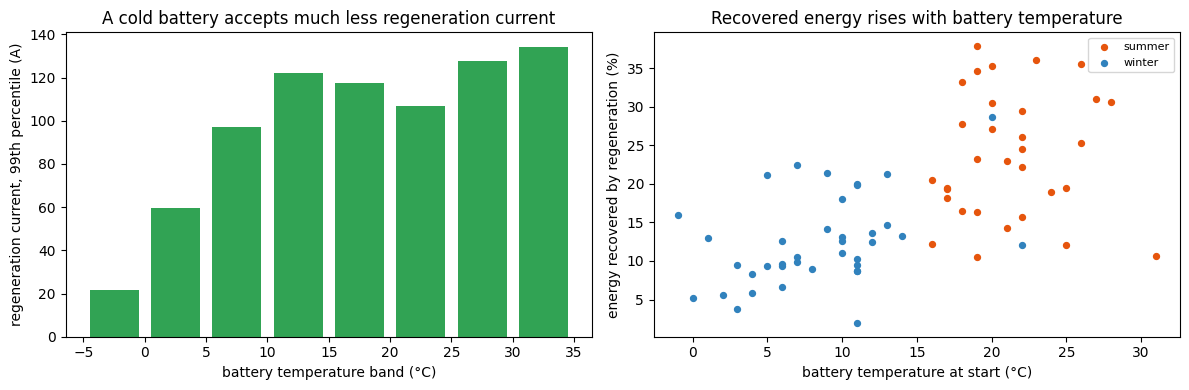

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(regen_limit.batt_temp_band_c + 2.5, regen_limit.regen_current_p99_a, width=4, color="#31a354")
axes[0].set(xlabel="battery temperature band (°C)", ylabel="regeneration current, 99th percentile (A)",
            title="A cold battery accepts much less regeneration current")
for s, c in SEASON_COLORS.items():
    d = trip[trip.season == s]
    axes[1].scatter(d.batt_temp_start_c, d.regen_share_pct, s=18, color=c, label=s)
axes[1].set(xlabel="battery temperature at start (°C)", ylabel="energy recovered by regeneration (%)",
            title="Recovered energy rises with battery temperature")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "04_regen_vs_battery_temp.png", dpi=150)
plt.show()

## 4 · Voltage sag vs temperature

Each sag event from notebook 03 carries an apparent pack resistance (sag ÷ extra current). Resistance, unlike raw sag
depth, does not depend on how hard the driver accelerated, so it is the fair quantity to compare across temperatures.

In [13]:
ev = con.sql("SELECT * FROM signal.sag_events WHERE apparent_resistance_mohm IS NOT NULL").df()
rho_t, p_t = stats.spearmanr(ev.batt_temp_c, ev.apparent_resistance_mohm)
rho_s, p_s = stats.spearmanr(ev.soc_pct, ev.apparent_resistance_mohm, nan_policy="omit")
rho_i, p_i = stats.spearmanr(-ev.current_at_max_sag_a, ev.max_sag_v)
print(f"events with a resistance estimate: {len(ev)}")
print(f"resistance vs battery temperature: rho = {rho_t:.2f} (p = {p_t:.2g})")
print(f"resistance vs SoC                 : rho = {rho_s:.2f} (p = {p_s:.2g})")
print(f"sag depth vs discharge current    : rho = {rho_i:.2f} (p = {p_i:.2g})")

bins = pd.cut(ev.batt_temp_c, [-5, 5, 10, 15, 20, 25, 35])
by_temp = ev.groupby(bins, observed=True).apparent_resistance_mohm.agg(events="size", median="median",
                                                                        q25=lambda x: x.quantile(.25),
                                                                        q75=lambda x: x.quantile(.75)).round(0)
by_temp

events with a resistance estimate: 556
resistance vs battery temperature: rho = -0.91 (p = 1.9e-213)
resistance vs SoC                 : rho = -0.09 (p = 0.04)
sag depth vs discharge current    : rho = 0.65 (p = 1.6e-68)


,events,median,q25,q75
batt_temp_c,,,,
"(-5, 5]",144,197.0,180.0,212.0
"(5, 10]",199,148.0,135.0,163.0
"(10, 15]",131,117.0,110.0,124.0
"(15, 20]",33,99.0,95.0,105.0
"(20, 25]",34,88.0,86.0,94.0
"(25, 35]",15,73.0,72.0,77.0


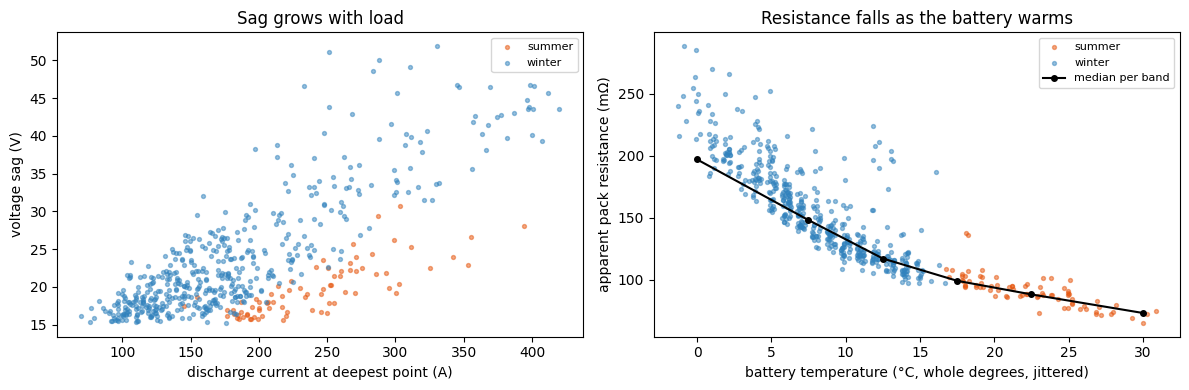

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for s, c in SEASON_COLORS.items():
    d = ev[ev.season == s]
    axes[0].scatter(-d.current_at_max_sag_a, d.max_sag_v, s=8, alpha=0.5, color=c, label=s)
    axes[1].scatter(d.batt_temp_c + np.random.default_rng(1).uniform(-0.3, 0.3, len(d)), d.apparent_resistance_mohm,
                    s=8, alpha=0.5, color=c, label=s)
mid = [iv.mid for iv in by_temp.index]
axes[1].plot(mid, by_temp["median"], "k-o", lw=1.5, ms=4, label="median per band")
axes[0].set(xlabel="discharge current at deepest point (A)", ylabel="voltage sag (V)", title="Sag grows with load")
axes[1].set(xlabel="battery temperature (°C, whole degrees, jittered)", ylabel="apparent pack resistance (mΩ)",
            title="Resistance falls as the battery warms")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "04_sag_vs_temperature.png", dpi=150)
plt.show()

## 5 · Correlations

**Trip level:** Spearman rank correlations between the main per-trip variables.
**Sample level:** while driving, how battery power relates to speed, acceleration and throttle (1 Hz subsample).

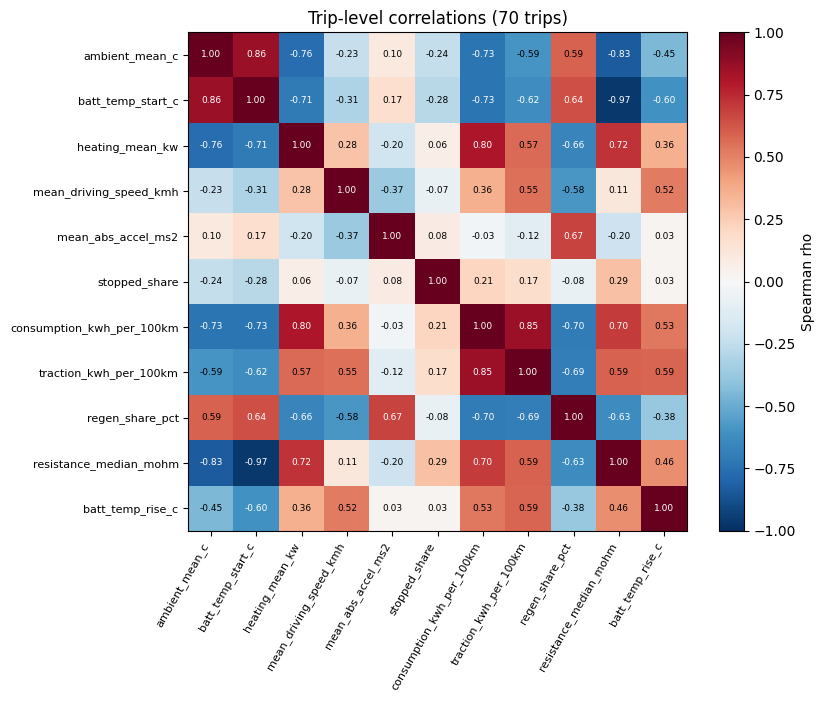

In [15]:
corr_cols = ["ambient_mean_c", "batt_temp_start_c", "heating_mean_kw", "mean_driving_speed_kmh", "mean_abs_accel_ms2",
             "stopped_share", "consumption_kwh_per_100km", "traction_kwh_per_100km", "regen_share_pct",
             "resistance_median_mohm", "batt_temp_rise_c"]
corr = trip[corr_cols].corr(method="spearman")
corr.round(2).to_csv(REPORTS / "04_trip_correlations.csv")

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr_cols)), corr_cols, fontsize=8)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(corr.iat[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Spearman rho")
ax.set_title("Trip-level correlations (70 trips)")
fig.tight_layout()
fig.savefig(FIGURES / "04_trip_correlations.png", dpi=150)
plt.show()

In [16]:
samp = con.sql("""
    SELECT s.power_smooth_kw, c.speed_kmh, c.accel_long_ms2, c.throttle_pct, c.motor_torque_nm, c.elevation_m,
           c.heating_power_can_kw, c.ambient_temp_c
    FROM clean.trip_signals c JOIN signal.samples s USING (trip_id, row_idx)
    WHERE s.phase = 'driving' AND c.row_idx % 10 = 0
""").df()
samp["discharge_power_kw"] = -samp.pop("power_smooth_kw")
sample_corr = samp.corr(method="spearman")["discharge_power_kw"].drop("discharge_power_kw").sort_values(key=abs, ascending=False)
print(f"driving samples at 1 Hz: {len(samp):,}")
sample_corr.round(2).to_frame("Spearman rho with discharge power")

driving samples at 1 Hz: 92,328


,Spearman rho with discharge power
motor_torque_nm,0.91
throttle_pct,0.87
accel_long_ms2,0.82
speed_kmh,0.38
heating_power_can_kw,0.18
ambient_temp_c,-0.13
elevation_m,-0.04


In [17]:
# strongest pairs at trip level (excluding a variable with itself and mirrored duplicates)
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("rho").reset_index()
pairs["abs"] = pairs.rho.abs()
pairs.sort_values("abs", ascending=False).head(10).drop(columns="abs").round(2)

,level_0,level_1,rho
17,batt_temp_start_c,resistance_median_mohm,-0.97
0,ambient_mean_c,batt_temp_start_c,0.86
45,consumption_kwh_per_100km,traction_kwh_per_100km,0.85
8,ambient_mean_c,resistance_median_mohm,-0.83
22,heating_mean_kw,consumption_kwh_per_100km,0.80
1,ambient_mean_c,heating_mean_kw,-0.76
5,ambient_mean_c,consumption_kwh_per_100km,-0.73
14,batt_temp_start_c,consumption_kwh_per_100km,-0.73
25,heating_mean_kw,resistance_median_mohm,0.72
10,batt_temp_start_c,heating_mean_kw,-0.71


## 7 · Findings

**1. Winter trips use about 43 % more energy per km.** Median consumption is 19.1 kWh/100 km in winter against
13.3 in summer (p < 0.001). Distance, acceleration and elevation range were similar, and speed was only slightly
higher in winter (p = 0.06). One difference does exist: winter trips spent more time stopped (12 % vs 9 %, p = 0.03).
While stopped the heater keeps running and no distance is gained, which adds to heating per km.

**2. Cabin heating is the largest single cause, and it is front-loaded.**
- Heating takes a median 18 % of winter battery energy (3.8 kWh/100 km), and up to 30 % in TripB02.
- Colder trips draw more heating power (rho = −0.39 within winter trips), and heating's share of battery energy falls as it gets warmer (rho = −0.77 over all trips). Summer trips use almost no heating once stale readings are removed (notebook 02, 3.5).
- Mean heating power is about 3.6 kW in the first 5 minutes and drops to about 1.2 kW after 15 minutes, once the cabin has warmed up.
- Short winter trips are therefore the least efficient.

**3. Without heating and A/C, winter is still about 3.1 kWh/100 km worse, and speed explains only a small part of it.**
After controlling for speed, the winter effect is still about +2.4 kWh/100 km. Speed-matched trips (45–65 km/h)
show 12.0 against 15.1 kWh/100 km. Part of it is
**regeneration limited by a cold battery**:
- The 99th-percentile regeneration current is about 22 A with the battery below 0 °C and about 60 A at 0–5 °C, against more than 120 A above 10 °C.
- Recovered energy halves in winter (12 % vs 23 % of energy drawn) and rises with battery temperature (rho = 0.64).
- The remaining gap (cold tyres, denser air, higher resistive losses) cannot be separated with this data. It is a hypothesis, not a finding.

**4. Pack resistance depends strongly on temperature.**
- Apparent resistance falls from about 197 mΩ below 5 °C to about 73 mΩ above 25 °C (rho = −0.91 over 556 events).
- SoC has almost no effect (rho = −0.09).
- At the same current, a cold pack sags much deeper, which is why winter trips show about 6× more sag events per 10 km.
- Across trips, battery temperature at the start ranks trips by median resistance almost perfectly (rho = −0.97).

**5. Correlations.**
- While driving, battery power follows motor torque, throttle and acceleration (rho 0.82–0.91), and speed only weakly (0.38).
- At trip level, temperature (ambient and battery) is the hub. It links consumption, heating, regeneration, resistance and battery warm-up.

**Caveats**
- There are only 70 trips, from one car and one driver group around Munich. The seasons also differ in route, so season effects are associations, not controlled experiments.
- Battery temperature is logged in whole degrees.
- Resistance is an *apparent* value (sag ÷ current), not a lab measurement.

**What this means for the next steps**
- Temperature (battery and ambient), heating power, speed and torque are the key inputs for the models (step 6).
- Cold-weather sag and the B02 heating event are natural anomaly candidates (step 7).

In [18]:
con.close()